# Chapter 4: Patterns Are the Point

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will compare a square network with a diamond network by pairing their points and carrying every link across. You will see how one failed link refutes a pairing without proving the networks differ, and then watch a row of cells in a mirror to learn the difference between something that survives a change (an invariant) and a true symmetry.

**A note before you start.** The code cells are optional reading. You do not need to run or understand them: the numbers and pictures they produce are already shown right below each one. If you are curious, read the code like a recipe, one line at a time.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch

INK, TEAL, GOLD, RED, GREY, NAVY = "#172a3b", "#0f6268", "#b8860b", "#a24a33", "#6b757b", "#1f3b5c"
PALE, PICK = "#e3efee", "#f3e1da"
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.edgecolor": GREY,
                     "axes.labelcolor": INK, "text.color": INK})

def blank(ax):
    """Hide ticks and frame so a drawing looks like a drawing."""
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)

def as_set(items):
    """Write a collection the way the book does: {3, 6, 9}."""
    items = list(items)
    return "{" + ", ".join(str(i) for i in items) + "}" if items else "{ }"

yn = lambda b: "yes" if b else "no"

## 1. Carry every link through the pairing

**The question.** The square and the diamond look different. Does a pairing of their points keep every link?

**The equations from the chapter.**

$$\text{A-B, A-C, B-D, C-D} \qquad\qquad \text{P-Q, P-R, Q-S, R-S}$$

**What the symbols mean.** A, B, C, D are the points of the first drawing; P, Q, R, S are the points of the second. A-B means a link joins A and B. An arrow such as A → P pairs a point with its partner. *Carrying a link* means replacing both of its endpoints by their partners. We start with the book's pairing: A → P, B → Q, C → R, D → S.

**Try to predict first.** Try the pairing that sends B to R and C to Q. Will all four carried links land on listed links?

In [2]:
source_links = [("A", "B"), ("A", "C"), ("B", "D"), ("C", "D")]
target_links = [("P", "Q"), ("P", "R"), ("Q", "S"), ("R", "S")]
source_pos = {"A": (0, 1), "B": (1, 1), "C": (0, 0), "D": (1, 0)}
target_pos = {"P": (0.5, 1.1), "Q": (1.1, 0.5), "R": (-0.1, 0.5), "S": (0.5, -0.1)}

pairings = {
    "book":     {"A": "P", "B": "Q", "C": "R", "D": "S"},
    "swapped":  {"A": "P", "B": "Q", "C": "S", "D": "R"},
    "other":    {"A": "P", "B": "R", "C": "Q", "D": "S"},
    "broken":   {"A": "P", "B": "S", "C": "R", "D": "Q"},
}

def listed(a, b):
    return (a, b) in target_links or (b, a) in target_links

def link_name(a, b):
    return f"{a}-{b}" if a < b else f"{b}-{a}"

def carry(mapping):
    rows = []
    for a, b in source_links:
        ta, tb = mapping[a], mapping[b]
        rows.append((link_name(a, b), link_name(ta, tb), listed(ta, tb)))
    return rows

def pairing_text(mapping):
    return ", ".join(f"{s} -> {t}" for s, t in mapping.items())

m = pairings["book"]
rows = carry(m)
print("Pairing:", pairing_text(m))
for src, dst, ok in rows:
    print(f"  link {src} becomes {dst}: {'listed' if ok else 'NOT listed'}")
kept = sum(ok for _, _, ok in rows)
print("Score 1 for each listed link:", " + ".join("1" if ok else "0" for *_, ok in rows), "=", kept, "of 4")
print("Every link arrives at a listed link, so this pairing preserves every link." if kept == 4 else "At least one link fails, so this pairing fails.")

Pairing: A -> P, B -> Q, C -> R, D -> S
  link A-B becomes P-Q: listed
  link A-C becomes P-R: listed
  link B-D becomes Q-S: listed
  link C-D becomes R-S: listed
Score 1 for each listed link: 1 + 1 + 1 + 1 = 4 of 4
Every link arrives at a listed link, so this pairing preserves every link.


All four pairings from the reader's menu:

In [3]:
for name, m in pairings.items():
    rows = carry(m)
    kept = sum(ok for *_, ok in rows)
    detail = "; ".join(f"{s} to {d}{'' if ok else ' (no link)'}" for s, d, ok in rows)
    print(f"{pairing_text(m)}")
    print(f"   {detail}")
    print(f"   score: {' + '.join('1' if ok else '0' for *_, ok in rows)} = {kept} of 4")

A -> P, B -> Q, C -> R, D -> S
   A-B to P-Q; A-C to P-R; B-D to Q-S; C-D to R-S
   score: 1 + 1 + 1 + 1 = 4 of 4
A -> P, B -> Q, C -> S, D -> R
   A-B to P-Q; A-C to P-S (no link); B-D to Q-R (no link); C-D to R-S
   score: 1 + 0 + 0 + 1 = 2 of 4
A -> P, B -> R, C -> Q, D -> S
   A-B to P-R; A-C to P-Q; B-D to R-S; C-D to Q-S
   score: 1 + 1 + 1 + 1 = 4 of 4
A -> P, B -> S, C -> R, D -> Q
   A-B to P-S (no link); A-C to P-R; B-D to Q-S; C-D to Q-R (no link)
   score: 0 + 1 + 1 + 0 = 2 of 4


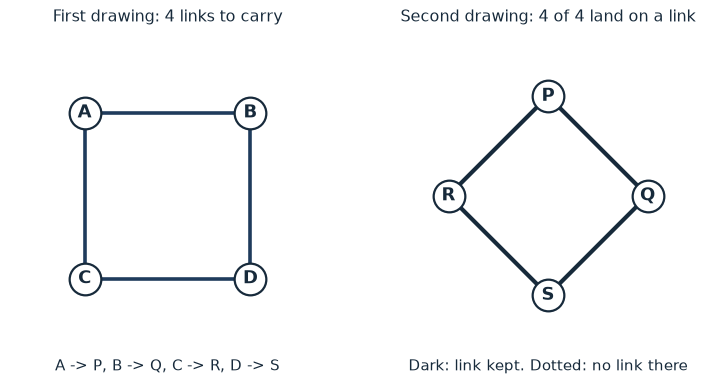

In [4]:
def network(ax, pos, links, title, colors=None, styles=None):
    for i, (a, b) in enumerate(links):
        (x0, y0), (x1, y1) = pos[a], pos[b]
        ax.plot([x0, x1], [y0, y1], color=colors[i] if colors else NAVY,
                linestyle=styles[i] if styles else "solid", linewidth=2.6, zorder=1)
    for name, (x, y) in pos.items():
        ax.scatter([x], [y], s=520, color="white", edgecolor=INK, linewidth=1.6, zorder=2)
        ax.text(x, y, name, ha="center", va="center", fontsize=13, fontweight="bold", zorder=3)
    ax.set_xlim(-0.45, 1.45); ax.set_ylim(-0.45, 1.5); ax.set_aspect("equal")
    blank(ax); ax.set_title(title, fontsize=11.5)

m = pairings["book"]
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 4.2))
network(left, source_pos, source_links, "First drawing: 4 links to carry")
# the diamond's own links, pale; carried links drawn dark when they land on a listed link
for a, b in target_links:
    (x0, y0), (x1, y1) = target_pos[a], target_pos[b]
    right.plot([x0, x1], [y0, y1], color="#d9d9d9", linewidth=2.0, zorder=1)
for a, b in source_links:
    ta, tb = m[a], m[b]
    (x0, y0), (x1, y1) = target_pos[ta], target_pos[tb]
    if listed(ta, tb):
        right.plot([x0, x1], [y0, y1], color=INK, linewidth=3.0, zorder=2)
    else:
        right.plot([x0, x1], [y0, y1], color=RED, linewidth=1.6, linestyle=":", zorder=2)
for name, (x, y) in target_pos.items():
    right.scatter([x], [y], s=520, color="white", edgecolor=INK, linewidth=1.6, zorder=3)
    right.text(x, y, name, ha="center", va="center", fontsize=13, fontweight="bold", zorder=4)
right.set_xlim(-0.45, 1.45); right.set_ylim(-0.45, 1.5); right.set_aspect("equal"); blank(right)
right.set_title(f"Second drawing: {sum(ok for *_, ok in carry(m))} of 4 land on a link", fontsize=11.5)
left.set_xlabel(pairing_text(m)); right.set_xlabel("Dark: link kept. Dotted: no link there")
plt.show()

**What this shows.** Each link of the square is redrawn on the diamond using the pairing: A-B becomes P-Q, A-C becomes P-R, B-D becomes Q-S, C-D becomes R-S. All four are listed, so $1 + 1 + 1 + 1 = 4$ of 4, and this pairing preserves every link. Two drawings that look different can show the same connections. When two diagrams claim to show the same connections, write the pairing first, then check each link in a small table instead of trusting how the shapes look.

**Where it stops working.** These are simple networks: no repeated links and no link from a point to itself. Matching counts of points and links never checks a particular pairing. If line length or direction carried meaning, links alone would not be enough.

## 2. One failed link is a counterexample

**The question.** If every count agrees, can a pairing still fail?

**The equations from the chapter.**

$$\text{A-C} \qquad\qquad \text{P-S}$$

**What the symbols mean.** A-C is a link in the first drawing. Under C → S, its endpoints become P and S, written P-S. The diamond's listed links are P-Q, P-R, Q-S, and R-S. We follow A-C under the **swapped** pairing: A → P, B → Q, C → S, D → R.

**Try to predict first.** Under the swapped pairing, follow A-B instead of A-C. Does that link survive, and does its survival rescue the pairing?

In [5]:
m = pairings["swapped"]
a, b = "A", "C"
ta, tb = m[a], m[b]
print("Pairing:", pairing_text(m))
print(f"Follow {a}-{b}: {a} -> {ta} and {b} -> {tb}, so {a}-{b} becomes {link_name(ta, tb)}")
print(f"Is {link_name(ta, tb)} in the diamond's list P-Q, P-R, Q-S, R-S?  {'yes' if listed(ta, tb) else 'no'}")
print("The counts still agree: 4 - 4 = 0 points apart and 4 - 4 = 0 links apart.")
print("One failed link refutes 'every link is preserved' for this pairing.")
print()
print("All four links under the swapped pairing:")
rows = carry(m)
for s, d, ok in rows:
    print(f"  {s} becomes {d}: {'listed' if ok else 'not listed'}")
print("Score:", " + ".join("1" if ok else "0" for *_, ok in rows), "=", sum(ok for *_, ok in rows), "of 4")
print()
r = pairings["book"]
print("Repair by exchanging where C and D go (C -> R, D -> S):")
print("  A-C becomes", link_name(r["A"], r["C"]), "(listed)")
print("  Score:", sum(ok for *_, ok in carry(r)), "of 4")

Pairing: A -> P, B -> Q, C -> S, D -> R
Follow A-C: A -> P and C -> S, so A-C becomes P-S
Is P-S in the diamond's list P-Q, P-R, Q-S, R-S?  no
The counts still agree: 4 - 4 = 0 points apart and 4 - 4 = 0 links apart.
One failed link refutes 'every link is preserved' for this pairing.

All four links under the swapped pairing:
  A-B becomes P-Q: listed
  A-C becomes P-S: not listed
  B-D becomes Q-R: not listed
  C-D becomes R-S: listed
Score: 1 + 0 + 0 + 1 = 2 of 4

Repair by exchanging where C and D go (C -> R, D -> S):
  A-C becomes P-R (listed)
  Score: 4 of 4


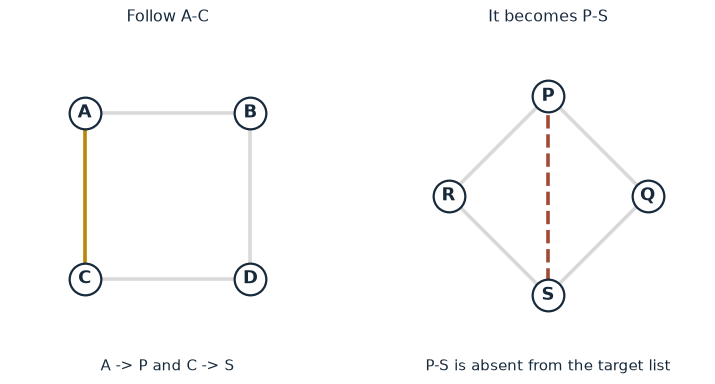

In [6]:
m = pairings["swapped"]
a, b = "A", "C"; ta, tb = m[a], m[b]
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 4.2))
src_colors = [GOLD if (x, y) == (a, b) else "#d9d9d9" for x, y in source_links]
network(left, source_pos, source_links, f"Follow {a}-{b}", src_colors)
tgt = target_links + [(ta, tb)]
cols = ["#d9d9d9"] * 4 + [RED]
network(right, target_pos, tgt, f"It becomes {link_name(ta, tb)}", cols, ["solid"] * 4 + ["dashed"])
left.set_xlabel(f"{a} -> {ta} and {b} -> {tb}")
right.set_xlabel(f"{link_name(ta, tb)} is absent from the target list")
plt.show()

**What this shows.** Under C → S, the link A-C becomes P-S, which the diamond does not have. That single link is the counterexample, even though both drawings have 4 points and 4 links. The same pairing keeps only $1 + 0 + 0 + 1 = 2$ of 4 links: A-B (to P-Q) and C-D (to R-S) survive, while A-C (to P-S) and B-D (to Q-R) fail. Exchanging the destinations of C and D repairs the pairing.

Keep the claim narrow: a failed pairing says *this assignment* does not work. It does not say the two diagrams have different structures.

**Where it stops working.** One failed link rules out only the pairing being tested. Ruling out every possible pairing would take many more checks.

## 3. What a reflection keeps and what it moves

**The question.** When a row of cells is reflected left to right, which features survive?

**The equation from the chapter.**

$$\text{black} \mid \text{white} \mid \text{white}$$

**What the symbols mean.** Each row has three cells, read left to right relative to the page. A left-right reflection reverses the order. An *invariant* is a feature that stays the same while something else changes. We start with black-white-white, the book's row.

**Try to predict first.** Choose white-black-white. After the reflection, is the leftmost color still the same? Is the number of black cells?

In [7]:
rows3 = {
    "black-white-white": ["black", "white", "white"],
    "white-black-white": ["white", "black", "white"],
    "black-black-white": ["black", "black", "white"],
    "white-white-black": ["white", "white", "black"],
}

def reflect_report(before):
    after = list(reversed(before))
    nb, na = before.count("black"), after.count("black")
    print(f"Before: {'-'.join(before)}")
    print(f"After reflection: {'-'.join(after)}   (the order is reversed)")
    print(f"Black cells: {nb} before and {na} after, and {na} - {nb} = {na - nb}, so the count is {'invariant' if na == nb else 'changed'}")
    print(f"Leftmost color: {before[0]} before, {after[0]} after, so it is {'preserved here' if before[0] == after[0] else 'changed'}")
    print()

reflect_report(rows3["black-white-white"])
print("The other rows from the menu:")
for name, r in list(rows3.items())[1:]:
    reflect_report(r)

Before: black-white-white
After reflection: white-white-black   (the order is reversed)
Black cells: 1 before and 1 after, and 1 - 1 = 0, so the count is invariant
Leftmost color: black before, white after, so it is changed

The other rows from the menu:
Before: white-black-white
After reflection: white-black-white   (the order is reversed)
Black cells: 1 before and 1 after, and 1 - 1 = 0, so the count is invariant
Leftmost color: white before, white after, so it is preserved here

Before: black-black-white
After reflection: white-black-black   (the order is reversed)
Black cells: 2 before and 2 after, and 2 - 2 = 0, so the count is invariant
Leftmost color: black before, white after, so it is changed

Before: white-white-black
After reflection: black-white-white   (the order is reversed)
Black cells: 1 before and 1 after, and 1 - 1 = 0, so the count is invariant
Leftmost color: white before, black after, so it is changed



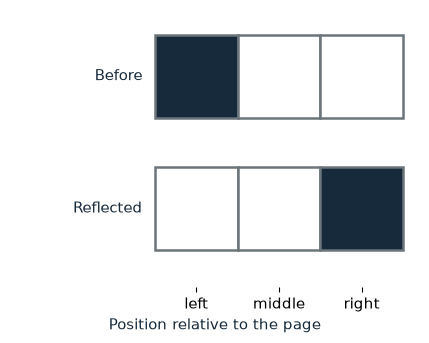

In [8]:
fill = {"black": INK, "white": "white"}
def draw_row(ax, cells_, y, show_fill=True):
    for i, c in enumerate(cells_):
        ax.add_patch(Rectangle((i, y), 1, 1, facecolor=fill[c] if show_fill else "white", edgecolor=GREY, linewidth=1.8))

def reflection_figure(before, show_fill=True, notes=None):
    after = list(reversed(before))
    fig, ax = plt.subplots(figsize=(8, 3.6))
    draw_row(ax, before, 1.7, show_fill); draw_row(ax, after, 0.1, show_fill)
    ax.text(-0.15, 2.2, "Before", ha="right", va="center"); ax.text(-0.15, 0.6, "Reflected", ha="right", va="center")
    if notes:
        for i, (txt, col) in enumerate(notes):
            ax.text(i + 0.5, 1.4, txt, ha="center", va="center", color=col, fontweight="bold", fontsize=10.5)
    ax.set_xlim(-1.75, 3.2); ax.set_ylim(-0.35, 3.0); ax.set_aspect("equal")
    ax.set_xticks([0.5, 1.5, 2.5]); ax.set_xticklabels(["left", "middle", "right"]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xlabel("Position relative to the page")
    plt.show()

reflection_figure(rows3["black-white-white"])

**What this shows.** The top row is the original and the bottom row is its mirror image. Black-white-white becomes white-white-black. The black count is the same before and after ($1 - 1 = 0$ change), so the count is an invariant. The leftmost color changed from black to white. A reflection never changes a cell's fill or the number of cells, so the black count is always invariant here, while the leftmost color can go either way. Before saying two pictures are the same, name the change and the feature you are checking, then check that feature before and after.

**Where it stops working.** "Left" means left on the page, and this is a three-cell row only.

## 4. An invariant is not yet a symmetry

**The question.** The black count survives the reflection. Does that make the reflection a symmetry of the row?

**The equation from the chapter.**

$$\text{white} \mid \text{white} \mid \text{black}$$

**What the symbols mean.** A *symmetry* is a transformation that leaves a stated object unchanged in a stated way. The *standard* says what counts as unchanged: the bare frame, the black count, or every filled position. We start with black-white-white judged by the **full filled arrangement**.

**Try to predict first.** Keep black-white-white and switch the standard from the black count to the full filled arrangement. Does the answer change?

In [9]:
def judge_symmetry(before, standard):
    after = list(reversed(before))
    matches = [b == a for b, a in zip(before, after)]
    if standard == "frame":
        return "3 cells before, 3 cells after: 3 - 3 = 0", True
    if standard == "count":
        n = before.count("black")
        return f"{n} black before, {n} black after: {n} - {n} = 0", True
    calc = f"positions that match: {' + '.join('1' if m else '0' for m in matches)} = {sum(matches)} of 3"
    return calc, all(matches)

names = {"frame": "the unfilled three-cell frame", "count": "the number of black cells", "full": "the full filled arrangement"}
for row_name in ["black-white-white", "white-black-white"]:
    r = rows3[row_name]
    print(f"Row {row_name} becomes {'-'.join(reversed(r))}")
    for std in ["full", "count", "frame"]:
        calc, same = judge_symmetry(r, std)
        print(f"  Standard: {names[std]:32s} Check: {calc:45s} unchanged? {'yes' if same else 'no'}")
    print()
print("The default state: black-white-white under the full filled arrangement.")
calc, same = judge_symmetry(rows3["black-white-white"], "full")
print(calc)
print("Not every position matches, so the reflection is not a symmetry of this filled row, even though the black count is invariant.")

Row black-white-white becomes white-white-black
  Standard: the full filled arrangement      Check: positions that match: 0 + 1 + 0 = 1 of 3      unchanged? no
  Standard: the number of black cells        Check: 1 black before, 1 black after: 1 - 1 = 0      unchanged? yes
  Standard: the unfilled three-cell frame    Check: 3 cells before, 3 cells after: 3 - 3 = 0      unchanged? yes

Row white-black-white becomes white-black-white
  Standard: the full filled arrangement      Check: positions that match: 1 + 1 + 1 = 3 of 3      unchanged? yes
  Standard: the number of black cells        Check: 1 black before, 1 black after: 1 - 1 = 0      unchanged? yes
  Standard: the unfilled three-cell frame    Check: 3 cells before, 3 cells after: 3 - 3 = 0      unchanged? yes

The default state: black-white-white under the full filled arrangement.
positions that match: 0 + 1 + 0 = 1 of 3
Not every position matches, so the reflection is not a symmetry of this filled row, even though the black count 

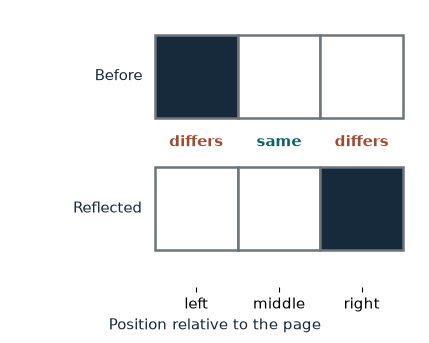

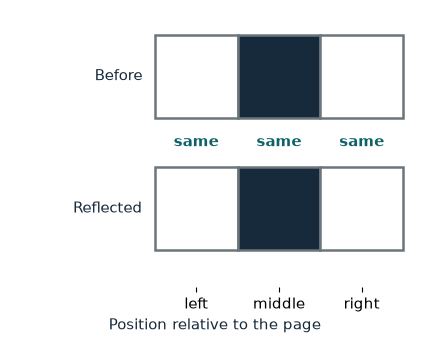

In [10]:
r = rows3["black-white-white"]
after = list(reversed(r))
notes = [("same" if b == a else "differs", TEAL if b == a else RED) for b, a in zip(r, after)]
reflection_figure(r, True, notes)
r2 = rows3["white-black-white"]
notes2 = [("same", TEAL)] * 3
reflection_figure(r2, True, notes2)

**What this shows.** The same reflection is judged by three standards. The frame and the count survive for any row. The full arrangement survives only when every position matches its mirror position. For black-white-white only 1 of 3 positions matches ($0 + 1 + 0 = 1$), so it is not a symmetry of the filled row, even though the black count is invariant. White-black-white matches in all three ($1 + 1 + 1 = 3$), so it is. When someone says two things are the same, ask for three items: the object, the allowed change, and the standard for unchanged.

**Where it stops working.** This covers a three-cell row and a left-right reflection only. Leaving out the fills is allowed only when the question is about the frame; once fills matter, they must be checked.

## Practice

**1.** Under A → P, B → S, C → R, D → Q, what does A-B become, and is it listed?

<details><summary>Show answer</summary>

A → P and B → S, so A-B becomes P-S. The diamond lists P-Q, P-R, Q-S, R-S, so P-S is not listed.

Carry the rest to score the pairing: A-C becomes P-R (listed), B-D becomes S-Q (listed), C-D becomes R-Q (not listed).

Score: $0 + 1 + 1 + 0 = 2$ of 4. One failed link already sinks this pairing.
</details>

**2.** A row black-black-white is reflected left to right. What is the new row, and what is its black count?

<details><summary>Show answer</summary>

Reverse the order: black-black-white becomes white-black-black.

Black cells: 2 before, 2 after, so $2 - 2 = 0$ change. The count is invariant. The leftmost color changes from black to white.
</details>

**3.** Does the row red-blue-red have left-right reflection symmetry with its fills included?

<details><summary>Show answer</summary>

Reverse the order: red-blue-red becomes red-blue-red.

Compare position by position: left is red and red (match), middle is blue and blue (match), right is red and red (match).

Matches: $1 + 1 + 1 = 3$ of 3, so yes, it is a symmetry.
</details>